# PhoBERT trên ViGoEmotions — 7 nhóm cảm xúc (Ekman + Neutral)


## 1. Cài đặt thư viện

In [ ]:
!pip install -q transformers==4.52.4

## 2. Cấu hình và đường dẫn

In [ ]:
import os, sys, json, re, time, random, glob
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules

# ======================= CẤU HÌNH =======================
SEED        = 42        
EPOCHS      = 12
BATCH_SIZE  = 32
LR          = 5e-5      
MAX_LEN     = 200       
THRESHOLD   = 0.5
MODEL_NAME  = 'vinai/phobert-base-v2'
MODEL_TAG   = 'phobert'

# 'model_text'        = tách từ bằng pyvi (giống repo gốc, giữ nguyên dữ liệu ViSoBERT đang dùng)
# 'model_text_vncore' = tách từ bằng VnCoreNLP (đúng định dạng pretrain của PhoBERT; cần cột này trong CSV)
# 'text'              = chưa tách từ (KHÔNG khuyến nghị cho PhoBERT)
TEXT_COL    = 'model_text'

POOLING     = 'mean'    # 'mean' | 'cls' | 'pooler' (pooler của PhoBERT khởi tạo ngẫu nhiên, tránh dùng)
USE_AMP     = False

EARLY_STOP_PATIENCE  = 3    # 0 = tắt early stopping
EARLY_STOP_MIN_DELTA = 0.0
RESUME      = True
DELETE_LAST_WHEN_DONE = True
SMOKE_TEST  = False     # True = chạy thử 1 epoch trên tập con nhỏ để kiểm tra pipeline
RUN_TAG     = ''

DATA_TAG     = 'data_ekman7'                    
VISOBERT_RUN = f'visobert_ekman7_seed{SEED}_mean'   
# =========================================================

if SMOKE_TEST:
    EPOCHS = 1

RUN_NAME = (f"{MODEL_TAG}_ekman7_seed{SEED}_{POOLING}_{TEXT_COL}"
            + ("_amp" if USE_AMP else "") + ("_smoke" if SMOKE_TEST else "") + (f"_{RUN_TAG}" if RUN_TAG else ""))


COLAB_REPO_ROOT = '/content/drive/MyDrive/DAP391m-sentiment-vn'

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    REPO_ROOT = Path(COLAB_REPO_ROOT)
else:
    REPO_ROOT = Path('..')
    if not (REPO_ROOT / 'notebooks').is_dir():   # chặn việc tạo runs/ nhầm chỗ khi sai thư mục chạy
        raise RuntimeError(f'Không thấy {REPO_ROOT.resolve()}/notebooks — hãy chạy notebook từ thư mục notebooks/ của repo.')

DATA_ROOT = (REPO_ROOT / 'data' / 'processed').as_posix()
OUT_ROOT  = (REPO_ROOT / 'runs').as_posix()

DATA_DIR = f'{DATA_ROOT}/{DATA_TAG}'
OUT_DIR  = f'{OUT_ROOT}/{RUN_NAME}'
os.makedirs(OUT_DIR, exist_ok=True)
for f in ['train.csv', 'val.csv', 'test.csv', 'label_dict_ekman7.json', 'ekman_mapping.json']:
    assert os.path.exists(f'{DATA_DIR}/{f}'), f'Thiếu {DATA_DIR}/{f} — hãy chạy notebook tiền xử lý trước (hoặc kiểm tra DATA_TAG).'

CONFIG = dict(seed=SEED, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, max_len=MAX_LEN, threshold=THRESHOLD,
              model_name=MODEL_NAME, model_tag=MODEL_TAG, text_col=TEXT_COL, pooling=POOLING, use_amp=USE_AMP,
              smoke=SMOKE_TEST, label_scheme='ekman7', data_tag=DATA_TAG,
              early_stop_patience=EARLY_STOP_PATIENCE, early_stop_min_delta=EARLY_STOP_MIN_DELTA)
with open(f'{OUT_DIR}/config.json', 'w') as f:
    json.dump(CONFIG, f, indent=2)

print('Run:', RUN_NAME)
print('Dữ liệu:', DATA_DIR)
print('Output dir:', OUT_DIR)
if POOLING == 'pooler':
    print('CẢNH BÁO: pooler của PhoBERT khởi tạo ngẫu nhiên; nên dùng POOLING="mean".')

Mounted at /content/drive
Run: phobert_ekman7_seed42_mean_model_text
Dữ liệu: /content/drive/MyDrive/vigo_runs/data_ekman7
Output dir: /content/drive/MyDrive/vigo_runs/phobert_ekman7_seed42_mean_model_text


## 3. Import, GPU, seed, ghi lại môi trường

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torch.optim import AdamW
import transformers
from transformers import AutoTokenizer, AutoModel, AutoConfig, get_scheduler
from sklearn.metrics import f1_score, classification_report
import matplotlib.pyplot as plt

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'KHÔNG CÓ GPU - hãy bật GPU trong Runtime')

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

env = dict(python=sys.version.split()[0], torch=torch.__version__, transformers=transformers.__version__,
           pandas=pd.__version__, numpy=np.__version__,
           gpu=torch.cuda.get_device_name(0) if device.type == 'cuda' else None)
import sklearn; env['scikit-learn'] = sklearn.__version__
with open(f'{OUT_DIR}/env.json', 'w') as f:
    json.dump(env, f, indent=2)
print(env)

Device: cuda:0 | Tesla T4
{'python': '3.13.16', 'torch': '2.11.0+cu130', 'transformers': '4.52.4', 'pandas': '2.2.3', 'numpy': '2.1.3', 'gpu': 'Tesla T4', 'scikit-learn': '1.6.1'}


## 4. Đọc dữ liệu đã tiền xử lý (7 nhóm)

In [ ]:
with open(f'{DATA_DIR}/label_dict_ekman7.json', 'r') as f:
    label_dict = json.load(f)               # {"0": "joy", ..., "6": "neutral"}
with open(f'{DATA_DIR}/ekman_mapping.json', 'r') as f:
    mapping = json.load(f)

N_LABELS = len(label_dict)
LABEL_NAMES = [label_dict[str(i)] for i in range(N_LABELS)]
assert LABEL_NAMES == mapping['group_names']
print('Số nhãn:', N_LABELS, LABEL_NAMES)

# ghi lại chính sách neutral của dữ liệu đang dùng, để đối chiếu với run ViSoBERT
manifest_path = f'{DATA_DIR}/manifest.json'
if os.path.exists(manifest_path):
    mf = json.load(open(manifest_path))
    print('Dữ liệu:', {k: mf.get(k) for k in ['preprocessing', 'neutral_policy', 'neutral_policy_applied_to_test', 'sizes']})
    CONFIG['neutral_policy'] = mf.get('neutral_policy')

def read_split(name):
    return pd.read_csv(f'{DATA_DIR}/{name}.csv', dtype={'id': str}, keep_default_na=False)

train_df, val_df, test_df = read_split('train'), read_split('val'), read_split('test')

if SMOKE_TEST:
    train_df, val_df, test_df = train_df.head(256), val_df.head(64), test_df.head(64)

for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    assert TEXT_COL in d.columns, (f'{name}.csv thiếu cột {TEXT_COL}. Các cột có: {list(d.columns)}. '
                                    f'Nếu dùng model_text_vncore, hãy thêm cột này ở notebook tiền xử lý.')
    assert (d[TEXT_COL].str.len() > 0).all(), f'{name} có văn bản rỗng'
    print(name, d.shape)
train_df[[TEXT_COL, 'labels', 'label_names']].head(3)

Số nhãn: 7 ['joy', 'sadness', 'anger', 'fear', 'surprise', 'disgust', 'neutral']
Dữ liệu: {'preprocessing': 'S1 (giữ emoji) + pyvi', 'neutral_policy': None, 'neutral_policy_applied_to_test': None, 'sizes': {'train': 16531, 'val': 2066, 'test': 2067}}
train (16531, 7)
val (2066, 7)
test (2067, 7)


,model_text,labels,label_names
0,xem mà ngẫm lại cuộc_đời bản_thân ta đã trải q...,[4],surprise
1,bức ảnh xuất_sắc ❤ ️,[0],joy
2,"vừa đẹp_trai , vừa tài_giỏi . nhà mặt_phố , bố...",[0],joy


## 5. Mã hóa nhãn (multi-hot, 7 nhóm)

Tần suất nhóm (train): {'joy': np.int64(8148), 'sadness': np.int64(4360), 'anger': np.int64(3903), 'fear': np.int64(1151), 'surprise': np.int64(2478), 'disgust': np.int64(1206), 'neutral': np.int64(821)}
Tỉ lệ lớn nhất/nhỏ nhất: 9.9x | số nhóm/mẫu trung bình: 1.33 | mẫu có >=2 nhóm: 30.1%


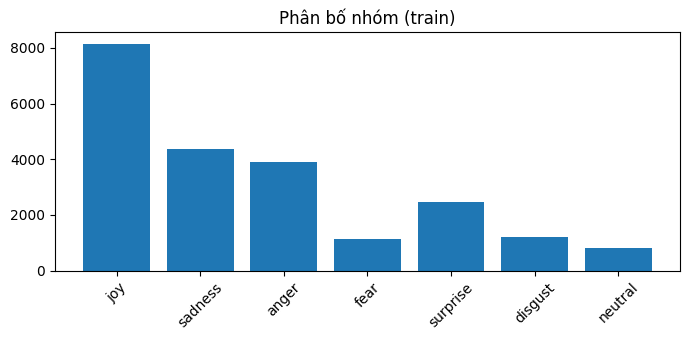

In [ ]:
def encode_labels(s):
    ids = [int(x) for x in re.findall(r'\d+', str(s))]
    assert ids and max(ids) < N_LABELS, s
    v = np.zeros(N_LABELS, dtype=np.float32)
    v[ids] = 1.0
    return v

Y_train = np.stack(train_df['labels'].apply(encode_labels).values)
Y_val   = np.stack(val_df['labels'].apply(encode_labels).values)
Y_test  = np.stack(test_df['labels'].apply(encode_labels).values)

label_counts = Y_train.sum(axis=0)
print('Tần suất nhóm (train):', dict(zip(LABEL_NAMES, label_counts.astype(int))))
print(f'Tỉ lệ lớn nhất/nhỏ nhất: {label_counts.max()/max(label_counts.min(),1):.1f}x | số nhóm/mẫu trung bình: {Y_train.sum(1).mean():.2f} | '
      f'mẫu có >=2 nhóm: {(Y_train.sum(1) >= 2).mean()*100:.1f}%')
plt.figure(figsize=(7, 3.5)); plt.bar(LABEL_NAMES, label_counts); plt.xticks(rotation=45); plt.title('Phân bố nhóm (train)'); plt.tight_layout(); plt.show()

## 6. Tokenizer và DataLoader

PhoBERT dùng tokenizer chậm (`use_fast=False`), đầu vào phải là văn bản đã tách từ (từ ghép nối bằng `_`). Ô dưới in thử một mẫu để bạn kiểm tra bằng mắt, và đo tỉ lệ `<unk>`: nếu cao thì emoji/teencode đang bị mất thông tin.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=False)

max_pos = AutoConfig.from_pretrained(MODEL_NAME).max_position_embeddings - 2   # RoBERTa trừ 2 vị trí đặc biệt
assert MAX_LEN <= max_pos, f'MAX_LEN={MAX_LEN} vượt quá giới hạn {max_pos} token của {MODEL_NAME}'

def encode(texts):
    enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN, padding='max_length',
                    return_attention_mask=True, return_token_type_ids=False, return_tensors='pt')
    return enc['input_ids'], enc['attention_mask']

t0 = time.time()
tr_ids, tr_mask = encode(train_df[TEXT_COL])
va_ids, va_mask = encode(val_df[TEXT_COL])
te_ids, te_mask = encode(test_df[TEXT_COL])
print(f'Tokenize xong ({time.time()-t0:.1f}s)')

# Ví dụ: kiểm tra việc tách từ có đúng dạng 'từ_ghép' hay không
ex = train_df[TEXT_COL].iloc[0]
print('Mẫu     :', ex)
print('Tokens  :', tokenizer.convert_ids_to_tokens(tr_ids[0][tr_mask[0].bool()].tolist()))

lens = tr_mask.sum(dim=1).numpy()
print(f'Token/mẫu (train): trung bình {lens.mean():.1f} | p95 {np.percentile(lens,95):.0f} | p99 {np.percentile(lens,99):.0f} | '
      f'bị cắt (chạm {MAX_LEN}): {(lens >= MAX_LEN).mean()*100:.2f}%')

# Tỉ lệ <unk>: emoji/teencode ngoài vocab sẽ rơi vào đây
unk = tokenizer.unk_token_id
for name, ids, mask in [('train', tr_ids, tr_mask), ('val', va_ids, va_mask), ('test', te_ids, te_mask)]:
    is_unk = (ids == unk) & (mask == 1)
    print(f'<unk> ({name}): {is_unk.sum().item() / mask.sum().item() * 100:.2f}% token | {is_unk.any(dim=1).float().mean().item() * 100:.1f}% câu có >=1 <unk>')

train_ds = TensorDataset(tr_ids, tr_mask, torch.from_numpy(Y_train))
val_ds   = TensorDataset(va_ids, va_mask, torch.from_numpy(Y_val))
test_ds  = TensorDataset(te_ids, te_mask, torch.from_numpy(Y_test))

train_gen = torch.Generator(); train_gen.manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  generator=train_gen, num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print('Số batch/epoch:', len(train_loader))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

bpe.codes: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenize xong (14.3s)
Mẫu     : xem mà ngẫm lại cuộc_đời bản_thân ta đã trải qua nhiều thứ ta rồi cũng sẽ lớn kí ước sẽ còn mãi trong lòng
Tokens  : ['<s>', 'xem', 'mà', 'ngẫm', 'lại', 'cuộc_đời', 'bản_thân', 'ta', 'đã', 'trải', 'qua', 'nhiều', 'thứ', 'ta', 'rồi', 'cũng', 'sẽ', 'lớn', 'kí', 'ước', 'sẽ', 'còn', 'mãi', 'trong', 'lòng', '</s>']
Token/mẫu (train): trung bình 18.6 | p95 47 | p99 86 | bị cắt (chạm 200): 0.01%
<unk> (train): 2.25% token | 25.6% câu có >=1 <unk>
<unk> (val): 2.27% token | 25.3% câu có >=1 <unk>
<unk> (test): 2.15% token | 26.6% câu có >=1 <unk>
Số batch/epoch: 517


## 7. Mô hình

In [ ]:
class ModelSentimentClassifier(nn.Module):
    def __init__(self, n_classes, model_name, pooling='mean'):
        super().__init__()
        self.pooling = pooling
        config = AutoConfig.from_pretrained(model_name, hidden_dropout_prob=0.1, attention_probs_dropout_prob=0.1)
        self.bert = AutoModel.from_pretrained(model_name, config=config)
        self.drop = nn.Dropout(p=0.2)
        self.fc = nn.Linear(self.bert.config.hidden_size, n_classes)

    def forward(self, input_ids, attention_mask):
        out = self.bert(input_ids=input_ids, attention_mask=attention_mask, return_dict=True)
        if self.pooling == 'mean':      # average pooling có mask: không tính token padding
            h = out.last_hidden_state.float()
            m = attention_mask.unsqueeze(-1).float()
            x = (h * m).sum(dim=1) / m.sum(dim=1).clamp(min=1e-9)
        elif self.pooling == 'pooler':
            x = out.pooler_output
        elif self.pooling == 'cls':
            x = out.last_hidden_state[:, 0]
        else:
            raise ValueError(f'POOLING không hợp lệ: {self.pooling}')
        return self.fc(self.drop(x))

set_seed(SEED)   # khởi tạo fc (và pooler nếu dùng) phụ thuộc seed
model = ModelSentimentClassifier(N_LABELS, MODEL_NAME, POOLING).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f'Tổng tham số: {n_params:,}')

pytorch_model.bin:   0%|          | 0.00/540M [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at vinai/phobert-base-v2 and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Tổng tham số: 135,003,655


## 8. Optimizer, scheduler, loss

In [ ]:
optimizer = AdamW(model.parameters(), lr=LR)
steps_per_epoch = len(train_loader)
scheduler = get_scheduler('linear', optimizer=optimizer, num_warmup_steps=steps_per_epoch,
                          num_training_steps=steps_per_epoch * EPOCHS)

# pos_weight tính từ train (clip count>=1 chỉ để smoke test không chia cho 0)
cnt = np.clip(label_counts, 1, None)
pos_weight = torch.tensor((len(Y_train) - cnt) / cnt, dtype=torch.float32).to(device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
scaler = torch.amp.GradScaler('cuda', enabled=(USE_AMP and device.type == 'cuda'))

## 9. Hàm train / eval

In [ ]:
def run_epoch(loader, train=False, return_probs=False):
    model.train(train)
    losses, all_t, all_p = [], [], []
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for ids, mask, y in loader:
            ids, mask, y = ids.to(device), mask.to(device), y.to(device)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(USE_AMP and device.type == 'cuda')):
                logits = model(ids, mask)
            loss = loss_fn(logits.float(), y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer); scaler.update()
                scheduler.step()
            losses.append(loss.item())
            all_t.append(y.cpu().numpy()); all_p.append(torch.sigmoid(logits.float()).detach().cpu().numpy())
    T, P = np.vstack(all_t), np.vstack(all_p)
    pred = (P >= THRESHOLD).astype(int)
    acc = (T == pred).mean(axis=0).mean()
    f1 = f1_score(T, pred, average='macro', zero_division=0)
    out = (float(np.mean(losses)), float(acc), float(f1))
    return out + (P, T) if return_probs else out

def save_atomic(obj, path):
    tmp = path + '.tmp'
    torch.save(obj, tmp); os.replace(tmp, path)

## 10. Huấn luyện (resume được, có early stopping)

Early stopping theo val Macro-F1; `best.pt` luôn là checkpoint tốt nhất theo val và mục 12 đánh giá từ `best.pt`. Lịch giảm lr được tính cho `EPOCHS` epoch nên khi dừng sớm lr chưa về 0. Nếu phiên Colab bị ngắt: mở lại và `Run all`, notebook tự tiếp tục từ `last.pt` với cùng cấu hình. Đổi cấu hình mà không đổi `RUN_NAME` sẽ báo lỗi thay vì resume nhầm.

In [ ]:
LAST, BEST, HIST, DONE = (f'{OUT_DIR}/{n}' for n in ['last.pt', 'best.pt', 'history.json', 'DONE'])

history, best_f1, start_epoch = [], 0.0, 0
bad_epochs, stopped = 0, False

if os.path.exists(DONE) and RESUME:
    print('Run này đã hoàn tất trước đó -> bỏ qua huấn luyện (xóa file DONE hoặc đổi SEED để chạy lại).')
    history = json.load(open(HIST))
    best_f1 = max(h['val_f1'] for h in history)
    start_epoch = EPOCHS
elif os.path.exists(LAST) and RESUME:
    ck = torch.load(LAST, map_location='cpu', weights_only=False)
    assert ck['config'] == CONFIG, f"Cấu hình checkpoint khác cấu hình hiện tại:\n{ck['config']}\n{CONFIG}"
    model.load_state_dict(ck['model']); optimizer.load_state_dict(ck['optimizer'])
    scheduler.load_state_dict(ck['scheduler']); scaler.load_state_dict(ck['scaler'])
    history, best_f1, start_epoch = ck['history'], ck['best_f1'], ck['epoch'] + 1
    bad_epochs = ck.get('bad_epochs', 0)
    stopped = EARLY_STOP_PATIENCE > 0 and bad_epochs >= EARLY_STOP_PATIENCE
    train_gen.set_state(ck['gen_state']); torch.set_rng_state(ck['rng_cpu'])
    if torch.cuda.is_available() and ck['rng_cuda'] is not None: torch.cuda.set_rng_state_all(ck['rng_cuda'])
    random.setstate(ck['rng_py']); np.random.set_state(ck['rng_np'])
    print(f'Resume từ epoch {start_epoch + 1}/{EPOCHS} (best val F1 hiện tại: {best_f1:.4f})')

t_start = time.time()
for epoch in range(start_epoch, EPOCHS):
    if stopped: break
    t0 = time.time()
    tr_loss, tr_acc, tr_f1 = run_epoch(train_loader, train=True)
    va_loss, va_acc, va_f1 = run_epoch(val_loader, train=False)
    history.append(dict(epoch=epoch + 1, lr=optimizer.param_groups[0]['lr'], train_loss=tr_loss, train_acc=tr_acc, train_f1=tr_f1,
                        val_loss=va_loss, val_acc=va_acc, val_f1=va_f1))
    improved = va_f1 > best_f1 + EARLY_STOP_MIN_DELTA
    bad_epochs = 0 if improved else bad_epochs + 1
    if improved:
        best_f1 = va_f1
        save_atomic(dict(model=model.state_dict(), epoch=epoch + 1, val_f1=va_f1, config=CONFIG), BEST)
    save_atomic(dict(model=model.state_dict(), optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(),
                     scaler=scaler.state_dict(), epoch=epoch, best_f1=best_f1, bad_epochs=bad_epochs, history=history, config=CONFIG,
                     gen_state=train_gen.get_state(), rng_cpu=torch.get_rng_state(),
                     rng_cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
                     rng_py=random.getstate(), rng_np=np.random.get_state()), LAST)
    json.dump(history, open(HIST, 'w'), indent=1)
    print(f'Epoch {epoch+1:>2}/{EPOCHS} | {time.time()-t0:5.0f}s | train loss {tr_loss:.4f} F1 {tr_f1:.4f} | '
          f'val loss {va_loss:.4f} F1 {va_f1:.4f}' + (' | *best*' if improved else f' | không cải thiện {bad_epochs}/{EARLY_STOP_PATIENCE}' if EARLY_STOP_PATIENCE > 0 else ''))
    if EARLY_STOP_PATIENCE > 0 and bad_epochs >= EARLY_STOP_PATIENCE:
        stopped = True
        print(f'Early stopping tại epoch {epoch+1}: val Macro-F1 không cải thiện {EARLY_STOP_PATIENCE} epoch liên tiếp (best {best_f1:.4f}).')
        break

if start_epoch < EPOCHS or stopped:
    open(DONE, 'w').write('done')
    if DELETE_LAST_WHEN_DONE and os.path.exists(LAST):
        os.remove(LAST)
    print(f'Hoàn tất. Thời gian phiên này: {(time.time()-t_start)/60:.1f} phút')

model.safetensors:   0%|          | 0.00/540M [00:00<?, ?B/s]

Resume từ epoch 11/12 (best val F1 hiện tại: 0.6611)
Epoch 11/12 |   580s | train loss 0.0786 F1 0.9712 | val loss 1.2345 F1 0.6569 | không cải thiện 2/3
Epoch 12/12 |   590s | train loss 0.0670 F1 0.9777 | val loss 1.2400 F1 0.6549 | không cải thiện 3/3
Early stopping tại epoch 12: val Macro-F1 không cải thiện 3 epoch liên tiếp (best 0.6611).
Hoàn tất. Thời gian phiên này: 19.5 phút


## 11. Đường cong huấn luyện

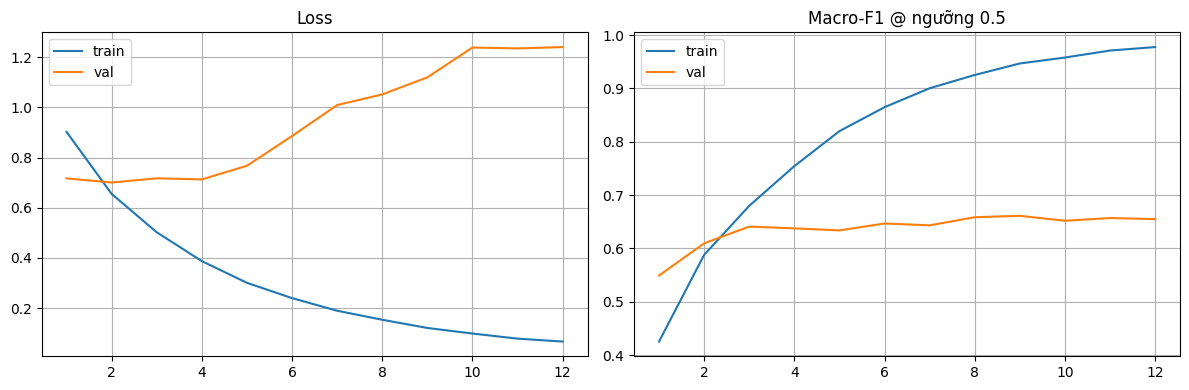

In [ ]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h['epoch'], h['train_loss'], label='train'); ax[0].plot(h['epoch'], h['val_loss'], label='val'); ax[0].set_title('Loss'); ax[0].legend(); ax[0].grid()
ax[1].plot(h['epoch'], h['train_f1'], label='train'); ax[1].plot(h['epoch'], h['val_f1'], label='val'); ax[1].set_title('Macro-F1 @ ngưỡng 0.5'); ax[1].legend(); ax[1].grid()
plt.tight_layout(); plt.show()

## 12. Đánh giá trên test + lưu xác suất

In [ ]:
ck = torch.load(BEST, map_location='cpu', weights_only=False)
model.load_state_dict(ck['model']); model.to(device)
print(f"Checkpoint tốt nhất: epoch {ck['epoch']} (val Macro-F1 {ck['val_f1']:.4f})")

_, _, val_f1, P_val, T_val   = run_epoch(val_loader,  return_probs=True)
_, _, test_f1, P_test, T_test = run_epoch(test_loader, return_probs=True)

np.save(f'{OUT_DIR}/val_probs.npy', P_val);   np.save(f'{OUT_DIR}/val_labels.npy', T_val)
np.save(f'{OUT_DIR}/test_probs.npy', P_test); np.save(f'{OUT_DIR}/test_labels.npy', T_test)

pred = (P_test >= THRESHOLD).astype(int)
rep = classification_report(T_test, pred, target_names=LABEL_NAMES, zero_division=0, output_dict=True)
pd.DataFrame(rep).transpose().to_excel(f'{OUT_DIR}/classification_report_test.xlsx')

print(classification_report(T_test, pred, target_names=LABEL_NAMES, zero_division=0))
macro, weighted = rep['macro avg']['f1-score'] * 100, rep['weighted avg']['f1-score'] * 100
micro   = f1_score(T_test, pred, average='micro',   zero_division=0) * 100
samples = f1_score(T_test, pred, average='samples', zero_division=0) * 100
exact   = (pred == T_test).all(axis=1).mean() * 100
print(f'TEST (7 nhóm, {MODEL_TAG})  Macro-F1 = {macro:.2f} | Weighted-F1 = {weighted:.2f} | Micro-F1 = {micro:.2f} | Samples-F1 = {samples:.2f} | Exact match = {exact:.2f}')
json.dump(dict(macro_f1=macro, weighted_f1=weighted, micro_f1=micro, samples_f1=samples, exact_match=exact,
               best_epoch=ck['epoch'], best_val_f1=ck['val_f1']), open(f'{OUT_DIR}/test_metrics.json', 'w'), indent=2)
if SMOKE_TEST:
    print('(SMOKE_TEST: số liệu trên chỉ để kiểm tra pipeline, không có ý nghĩa.)')

Checkpoint tốt nhất: epoch 9 (val Macro-F1 0.6611)
              precision    recall  f1-score   support

         joy       0.83      0.88      0.85      1019
     sadness       0.70      0.81      0.75       528
       anger       0.66      0.81      0.73       485
        fear       0.63      0.63      0.63       151
    surprise       0.58      0.68      0.63       310
     disgust       0.45      0.55      0.50       141
     neutral       0.47      0.45      0.46       116

   micro avg       0.70      0.78      0.74      2750
   macro avg       0.62      0.69      0.65      2750
weighted avg       0.70      0.78      0.74      2750
 samples avg       0.76      0.82      0.76      2750

TEST (7 nhóm, phobert)  Macro-F1 = 64.85 | Weighted-F1 = 73.77 | Micro-F1 = 73.70 | Samples-F1 = 76.33 | Exact match = 52.39


## 13. Ma trận nhầm lẫn theo từng nhóm (multi-label)

Mỗi ô là tỉ lệ mẫu **thật sự có nhóm hàng** mà mô hình **dự đoán có nhóm cột** (đường chéo = recall).

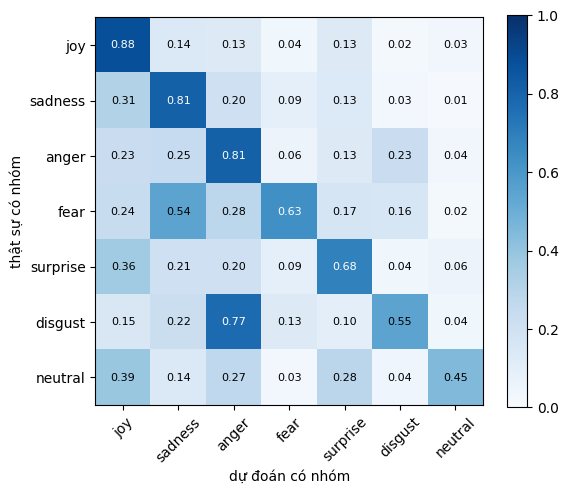

In [ ]:
T_i = T_test.astype(int)
M = np.zeros((N_LABELS, N_LABELS))
for i in range(N_LABELS):
    rows = T_i[:, i] == 1
    M[i] = pred[rows].mean(axis=0) if rows.any() else 0
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(M, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(N_LABELS)); ax.set_xticklabels(LABEL_NAMES, rotation=45); ax.set_yticks(range(N_LABELS)); ax.set_yticklabels(LABEL_NAMES)
ax.set_xlabel('dự đoán có nhóm'); ax.set_ylabel('thật sự có nhóm')
for i in range(N_LABELS):
    for j in range(N_LABELS): ax.text(j, i, f'{M[i,j]:.2f}', ha='center', va='center', fontsize=8, color='white' if M[i,j] > .6 else 'black')
plt.colorbar(im); plt.tight_layout(); plt.show()

In [1]:
import pandas as pd
rpt = pd.read_excel("../runs/PhoBERT/classification_report_test.xlsx", index_col=0)
print(f"PhoBERT — Test F1-macro: {rpt.loc['macro avg','f1-score']*100:.2f}%  |  F1-weighted: {rpt.loc['weighted avg','f1-score']*100:.2f}%")
print(rpt.round(4))

PhoBERT — Test F1-macro: 64.85%  |  F1-weighted: 73.77%
              precision  recall  f1-score  support
joy              0.8250  0.8793    0.8513     1019
sadness          0.6966  0.8087    0.7485      528
anger            0.6639  0.8103    0.7298      485
fear             0.6291  0.6291    0.6291      151
surprise         0.5761  0.6839    0.6254      310
disgust          0.4529  0.5461    0.4952      141
neutral          0.4727  0.4483    0.4602      116
micro avg        0.6964  0.7825    0.7370     2750
macro avg        0.6166  0.6865    0.6485     2750
weighted avg     0.6992  0.7825    0.7377     2750
samples avg      0.7624  0.8210    0.7633     2750
